Лабораторная работа №3. Регрессия.
Выполнил: студент Михайлов А.О. Группа: 4313

Подкотовка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Настраиваем графики на весь проект
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

#Загружаем данные
data = pd.read_csv('Electric_Vehicle_Population_Data.csv')

print(data.head)

<bound method NDFrame.head of         VIN (1-10)     County           City State  Postal Code  Model Year  \
0       JTMEB3FV6N     Monroe       Key West    FL        33040        2022   
1       1G1RD6E45D      Clark       Laughlin    NV        89029        2013   
2       JN1AZ0CP8B     Yakima         Yakima    WA        98901        2011   
3       1G1FW6S08H     Skagit       Concrete    WA        98237        2017   
4       3FA6P0SU1K  Snohomish        Everett    WA        98201        2019   
...            ...        ...            ...   ...          ...         ...   
112629  7SAYGDEF2N       King         Duvall    WA        98019        2022   
112630  1N4BZ1CP7K   San Juan  Friday Harbor    WA        98250        2019   
112631  1FMCU0KZ4N       King         Vashon    WA        98070        2022   
112632  KNDCD3LD4J       King      Covington    WA        98042        2018   
112633  YV4BR0CL8N       King      Covington    WA        98042        2022   

             Make    

Визуализация данных датасета

Гистограммы

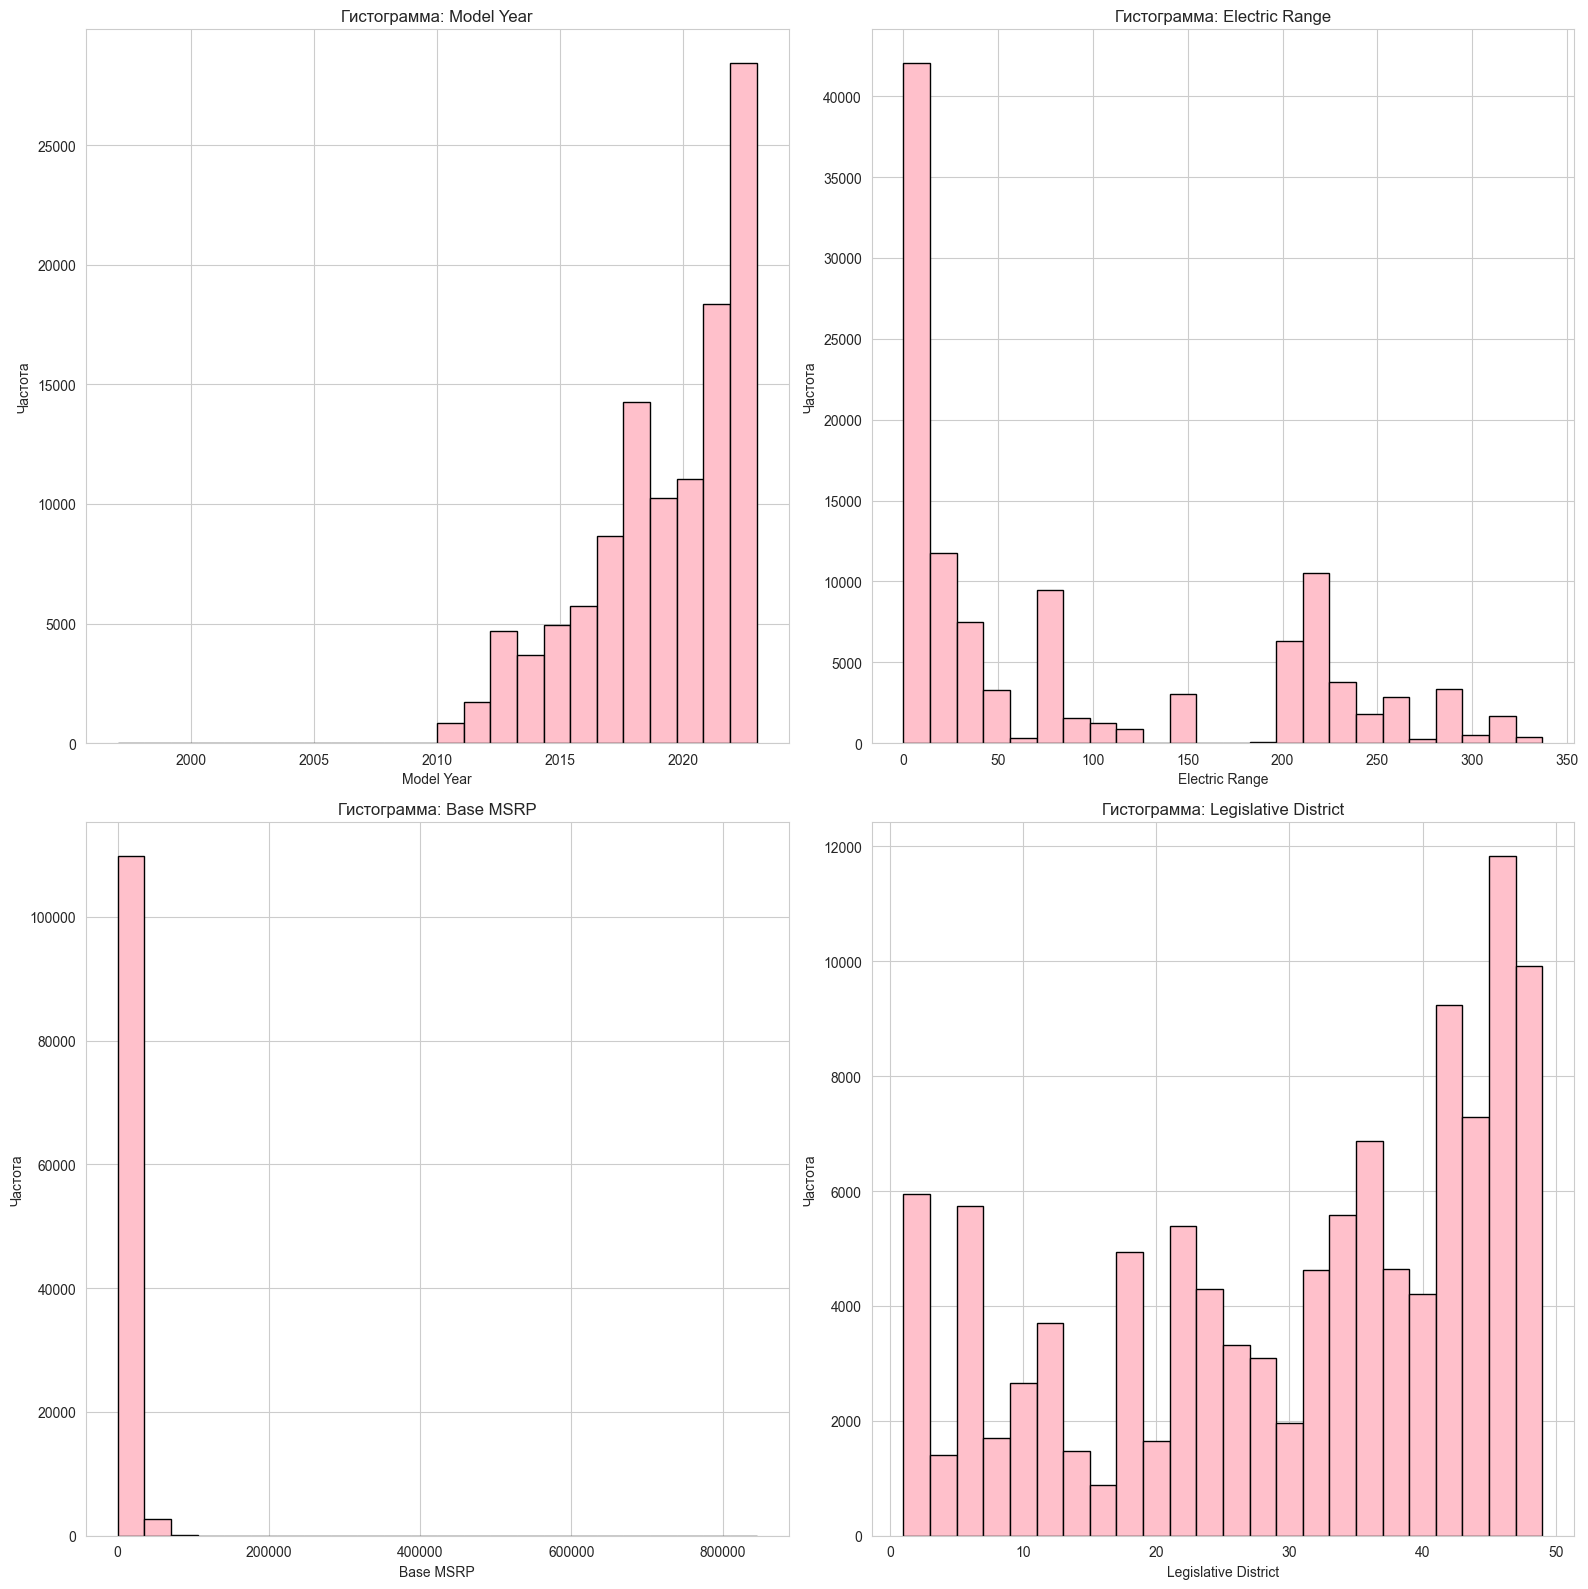

In [6]:
numeric_cols = ['Model Year', 'Electric Range', 'Base MSRP', 'Legislative District']

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(data[col].dropna(), bins=24, edgecolor='black', color='pink')
    axes[i].set_title(f'Гистограмма: {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()

Ящик с усами

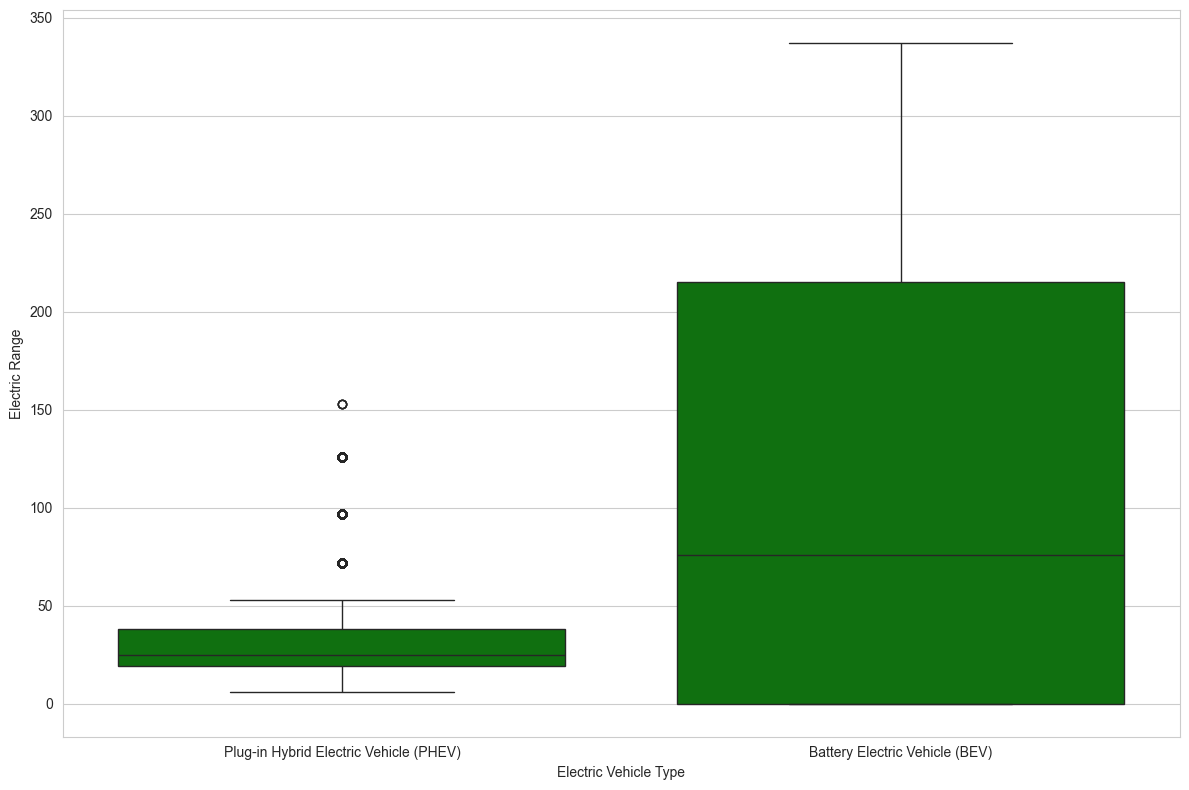

In [17]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=data, x='Electric Vehicle Type', y='Electric Range', color='green')
plt.tight_layout()
plt.show()

Топ-5 марок с наибольшим запасом хода

Text(0.5, 1.0, 'Топ-5 марок по лучшему среднему запасу хода')

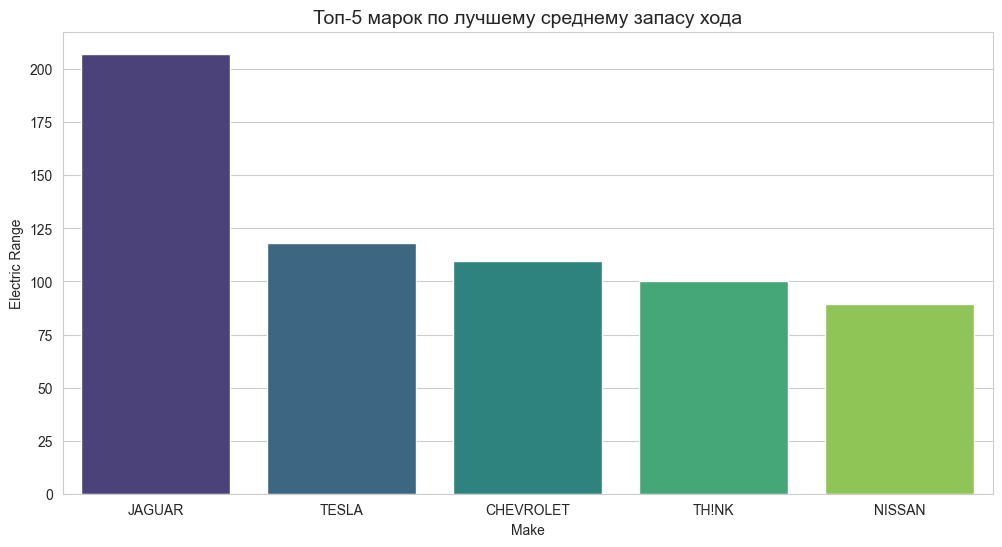

In [42]:
avg_el_range = data.groupby('Make')['Electric Range'].mean().reset_index()
top_high_range = avg_el_range.sort_values(by='Electric Range', ascending=False).head(5)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_high_range, x='Make', y='Electric Range', hue='Make', palette='viridis', legend=False)
plt.title('Топ-5 марок по лучшему среднему запасу хода', fontsize=14)

Топ-5 марок с наименьшим запасом хода

Text(0.5, 1.0, 'Топ-5 марок по худшему среднему запасу хода')

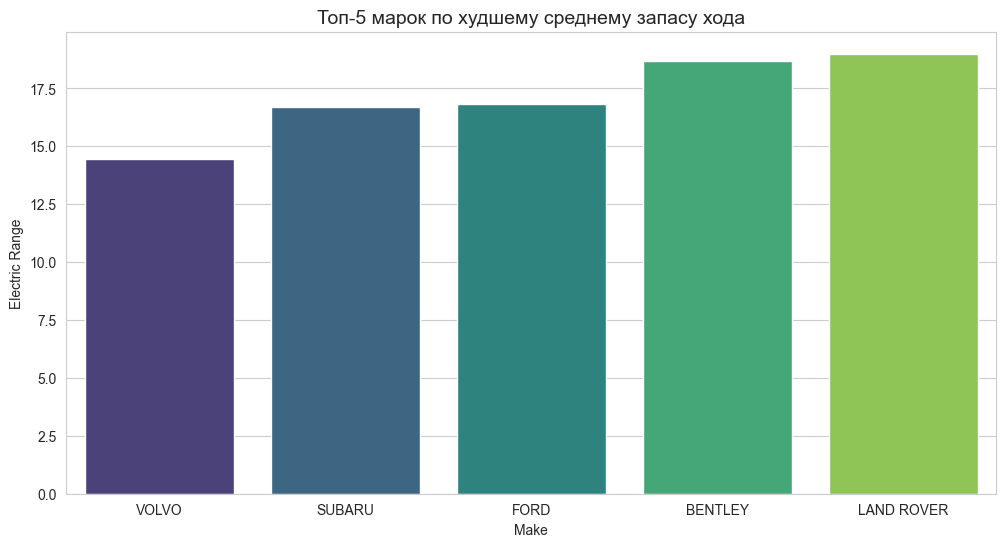

In [ ]:
avg_el_range = data.groupby('Make')['Electric Range'].mean().reset_index()
top_low_range = avg_el_range.sort_values(by='Electric Range', ascending=True)
top_low_range_filtered = top_low_range[top_low_range['Electric Range'] > 0].head(5)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_low_range_filtered, x='Make', y='Electric Range', hue='Make', palette='viridis', legend=False)
plt.title('Топ-5 марок по худшему среднему запасу хода', fontsize=14)

Предварительная обработка данных: очистка данных (удаление пропусков, дубликатов, нормализация)

Удаляем ненужные столбцы

In [44]:
columns_to_drop = [
    'VIN (1-10)',        #Уникальный ID машины, никак не влияет на запас хода
    'DOL Vehicle ID',    #Еще один технический ID, бесполезен для модели
    'Vehicle Location',  #Координаты (POINT), из них сложно вытащить смысл для базовой модели
    '2020 Census Tract', #Номер района переписи, не имеет физического смысла для батареи
    'Base MSRP',         #Рекомендованная цена, там 99% нулей (нет данных)
    'State',             #Почти все машины из штата WA (Вашингтон), признак бесполезен
    'City',              #Слишком много уникальных городов, зашумит модель
    'Clean Alternative Fuel Vehicle (CAFV) Eligibility' #утечка данных
]

data_clean = data.drop(columns=columns_to_drop)
print("Было колонок: ", data.shape[1])
print("Стало колонок: ", data_clean.shape[1])

print("\n", data_clean.columns.tolist())

Было колонок:  17
Стало колонок:  9

 ['County', 'Postal Code', 'Model Year', 'Make', 'Model', 'Electric Vehicle Type', 'Electric Range', 'Legislative District', 'Electric Utility']
